In [1]:
import os
import warnings
import logging
import torch

# Optional imports (only needed if you run CLIP/CLAP feature extraction later)
try:
    import clip
except Exception as e:
    clip = None
    print(f"[WARN] clip import failed: {e}")

try:
    import laion_clap
except Exception as e:
    laion_clap = None
    print(f"[WARN] laion_clap import failed: {e}")

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
logging.getLogger('librosa').setLevel(logging.ERROR)


/home/oem/anaconda3/envs/qx_llm/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
2026-01-29 00:34:11.206618: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-01-29 00:34:11.210359: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-01-29 00:34:11.217754: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1769614451.230068 2819244 cuda_dnn.cc:85

PyTorch version: 2.2.0+cu118
CUDA available: True


In [2]:
import os
import re
import numpy as np
import pandas as pd

# =========================
# UDIVA v0.5 path config
# =========================
UDIVA_BASE = "/data/qx/UDIVA_v0.5"
SPLIT_TRAIN = "train"
SPLIT_VAL   = "val"

TRAIN_RECORDINGS_ROOT = os.path.join(UDIVA_BASE, SPLIT_TRAIN, "recordings")
VAL_RECORDINGS_ROOT   = os.path.join(UDIVA_BASE, SPLIT_VAL,   "recordings")

TRAIN_TRANS_ROOT = os.path.join(UDIVA_BASE, SPLIT_TRAIN, "transcriptions")
VAL_TRANS_ROOT   = os.path.join(UDIVA_BASE, SPLIT_VAL,   "transcriptions")

TRAIN_LABEL_CSV = os.path.join(UDIVA_BASE, SPLIT_TRAIN, "metadata", "parts_train.csv")
VAL_LABEL_CSV   = os.path.join(UDIVA_BASE, SPLIT_VAL,   "metadata", "parts_val_unmasked.csv")

LABEL_COLS = [
    "OPENMINDEDNESS_Z",
    "CONSCIENTIOUSNESS_Z",
    "EXTRAVERSION_Z",
    "AGREEABLENESS_Z",
    "NEGATIVEEMOTIONALITY_Z",
]

TASKS = ("animals", "ghost", "lego", "talk")
VIDEO_EXTS = (".mp4", ".avi", ".mov", ".mkv")

def _build_gt_dict(csv_path: str, encoding: str = "ms932"):
    df = pd.read_csv(csv_path, encoding=encoding, sep=",")
    df = df[["ID"] + LABEL_COLS].copy()
    df["ID"] = df["ID"].apply(lambda x: int(str(x).strip()))
    for c in LABEL_COLS:
        df[c] = df[c].astype(float)
    return df.set_index("ID")[LABEL_COLS].to_dict(orient="index")  # {ID(int): {col: val}}

def _parse_subject_id_from_filename(fn: str):
    base = os.path.basename(fn)
    if len(base) >= 3 and base[:3].isdigit():
        return int(base[:3])
    m = re.search(r"\d{3}", base)
    return int(m.group()) if m else None

def _infer_task_from_recordings_class(cls_name: str):
    # e.g., animals_recordings_train -> animals
    s = cls_name.lower()
    for t in TASKS:
        if s.startswith(t + "_"):
            return t
    return None

def _build_transcript_path(trans_root: str, split: str, task: str, pair_folder: str):
    """
    Expected UDIVA transcripts layout (based on your screenshot):
      {trans_root}/{task}_transcripts_{split}/{pair_folder}/{pair_folder}_{task}.srt

    Example:
      /data/qx/UDIVA_v0.5/train/transcriptions/animals_transcripts_train/002003/002003_animals.srt
    """
    candidate = os.path.join(
        trans_root,
        f"{task}_transcripts_{split}",
        pair_folder,
        f"{pair_folder}_{task}.srt"
    )
    if os.path.exists(candidate):
        return candidate

    # 兜底：如果命名有细微差异（比如 .txt 或文件名不同），就到目录里找一个最像的 .srt
    folder = os.path.join(trans_root, f"{task}_transcripts_{split}", pair_folder)
    if os.path.isdir(folder):
        srt_files = [f for f in os.listdir(folder) if f.lower().endswith(".srt")]
        if len(srt_files) == 1:
            return os.path.join(folder, srt_files[0])
        # 优先选包含 task 的
        for f in srt_files:
            if task in f.lower():
                return os.path.join(folder, f)

    return None  # 没找到就返回 None

def load_udiva_video_text_paths_and_labels(
    recordings_root: str,
    trans_root: str,
    split: str,
    label_csv: str,
    encoding: str = "ms932",
    exts=VIDEO_EXTS,
    verbose: bool = False
):
    gt = _build_gt_dict(label_csv, encoding=encoding)

    video_paths = []
    text_paths  = []
    labels      = []

    for cls_name in sorted(os.listdir(recordings_root)):
        cls_path = os.path.join(recordings_root, cls_name)
        if not os.path.isdir(cls_path):
            continue

        task = _infer_task_from_recordings_class(cls_name)
        if task is None:
            # 跳过不认识的目录（比如 index.html 已经被 isdir 过滤了）
            continue

        for pair_folder in sorted(os.listdir(cls_path)):
            pair_path = os.path.join(cls_path, pair_folder)
            if not os.path.isdir(pair_path):
                continue

            # 这个 pair/task 对应的 transcript 通常是“共享的”（同一对人的同一任务一份 .srt）
            transcript_path = _build_transcript_path(trans_root, split, task, pair_folder)

            # 递归收集该 pair 下所有视频
            for root, _, files in os.walk(pair_path):
                for fn in files:
                    if not fn.lower().endswith(exts):
                        continue

                    sid = _parse_subject_id_from_filename(fn)
                    if sid is None or sid not in gt:
                        continue

                    vpath = os.path.join(root, fn)
                    video_paths.append(vpath)
                    text_paths.append(transcript_path)  # 每个视频挂同一个 transcript（同 pair/task）
                    labels.append([gt[sid][c] for c in LABEL_COLS])

                    if verbose:
                        print(f"[OK] task={task} pair={pair_folder} file={fn} sid={sid} text={transcript_path}")

    labels = np.asarray(labels, dtype=np.float32)
    return video_paths, text_paths, labels

train_v_paths, train_t_paths, train_labels = load_udiva_video_text_paths_and_labels(
    TRAIN_RECORDINGS_ROOT, TRAIN_TRANS_ROOT, SPLIT_TRAIN, TRAIN_LABEL_CSV, verbose=False
)
val_v_paths, val_t_paths, val_labels = load_udiva_video_text_paths_and_labels(
    VAL_RECORDINGS_ROOT, VAL_TRANS_ROOT, SPLIT_VAL, VAL_LABEL_CSV, verbose=False
)

print("Train samples:", len(train_v_paths), "labels shape:", train_labels.shape, "text missing:", sum([p is None for p in train_t_paths]))
print("Val samples:  ", len(val_v_paths),   "labels shape:", val_labels.shape,   "text missing:", sum([p is None for p in val_t_paths]))

# 例子：看一条对齐结果
if len(train_v_paths) > 0:
    print("Example:")
    print(" video:", train_v_paths[0])
    print(" text :", train_t_paths[0])
    print(" y    :", train_labels[0])


Train samples: 6516 labels shape: (6516, 5) text missing: 0
Val samples:   1100 labels shape: (1100, 5) text missing: 0
Example:
 video: /data/qx/UDIVA_v0.5/train/recordings/animals_recordings_train/002003/003_FC2_A_008.mp4
 text : /data/qx/UDIVA_v0.5/train/transcriptions/animals_transcripts_train/002003/002003_animals.srt
 y    : [-0.26390773  0.61615187  0.24308339  0.982578   -0.43797207]


In [3]:
import re
from datetime import timedelta

def parse_srt(file_path):
    with open(file_path, 'r', encoding='utf-8') as file:
        srt_text = file.read()
    
    pattern = re.compile(r"""(\d+)\n([\d:,]+) --> ([\d:,]+)\n(.+?)\n\n""", re.DOTALL)
    entries = []
    
    for match in pattern.finditer(srt_text):
        try:
            start_time = parse_time(match.group(2))
            end_time = parse_time(match.group(3))
            text = match.group(4).replace("\n", " ") 
            entries.append((start_time, end_time, text))
        except ValueError as e:
            print(f"skip: {match.group(2)} --> {match.group(3)}, error: {e}")
    
    return entries

def parse_time(time_str):
    """return timedelta"""
    parts = re.split('[:,]', time_str)
    if len(parts) == 4:  
        h, m, s, ms = map(int, parts)
    elif len(parts) == 3: 
        h, m, s = map(int, parts[:3])
        ms = int(parts[2].split('.')[1]) if '.' in parts[2] else 0  
    else:
        raise ValueError(f"Unable to resolve timestamp: {time_str}")

    return timedelta(hours=h, minutes=m, seconds=s, milliseconds=ms)

def split_by_minute(entries):
    """split the transcriptions into 1 min"""
    result = []
    start_time = timedelta(minutes=0)
    end_time = start_time + timedelta(minutes=1)
    current_segment = []
    last_overflow = None
    
    for entry in entries:
        entry_start, entry_end, text = entry
        
        if entry_start == timedelta(seconds=0):
            entry_start = timedelta(milliseconds=1)  
        
        if last_overflow and entry_start >= end_time:
            last_overflow = None
        
        if entry_end <= end_time or (last_overflow and entry == last_overflow):
            current_segment.append(text)
        else:
            last_overflow = entry
            
            if current_segment:
                result.append((start_time, end_time, " ".join(current_segment)))
            
            start_time = end_time
            end_time = start_time + timedelta(minutes=1)
            current_segment = [text]
    
    if current_segment:
        result.append((start_time, end_time, " ".join(current_segment)))
    
    return result
def extract_speaker_text(text):
    """ extract PART.1 and PART.2  """
    part1_texts = []
    part2_texts = []

    lines = text.split("PART.")
    for line in lines:
        if line.startswith("1:"):
            part1_texts.append(line[2:].strip())  
        elif line.startswith("2:"):
            part2_texts.append(line[2:].strip())  

    return " ".join(part1_texts), " ".join(part2_texts)

def transcriptions_extract(transcriptions_filepath,video_path):
    try:
        entries = parse_srt(transcriptions_filepath)
    except UnicodeDecodeError:
        logger.debug(f"Skip file: {transcriptions_filepath}，can`t use UTF-8 解码")#
        return None
    file_name = os.path.basename(video_path)
    segments = split_by_minute(entries)
    count = int(file_name[10:13])
    part = int(file_name[6])
    part_segments = []
    try:
        sigment = segments[count-1]
    except IndexError:
        logger.debug(f"Skip file: {transcriptions_filepath}，although there have video, there no text in the viideo ")
        return None
    text = sigment[2]#셋번째는 text
    # print(sigment[0],"-------->",sigment[1])
    part1_text, part2_text = extract_speaker_text(text)
    if part == 1:
        return part1_text
    elif part == 2:
        return part2_text

In [4]:
import os
import re
import cv2
import torch
import librosa
import numpy as np
import h5py
from PIL import Image
from tqdm import tqdm
from torch.utils.data import Dataset

# -------------------------
# SRT -> plain text
# -------------------------
_SRT_TIME_RE = re.compile(r"^\d{2}:\d{2}:\d{2}[,.]\d{3}\s*-->\s*\d{2}:\d{2}:\d{2}[,.]\d{3}$")

def read_srt_as_text(srt_path: str) -> str:
    """
    Convert .srt into a single plain text string:
    - drop index lines
    - drop timestamp lines
    - keep subtitle text lines
    """
    if srt_path is None or (isinstance(srt_path, str) and len(srt_path) == 0):
        return ""
    if not os.path.exists(srt_path):
        return ""

    lines_out = []
    with open(srt_path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            if line.isdigit():
                continue
            if _SRT_TIME_RE.match(line):
                continue
            lines_out.append(line)
    return " ".join(lines_out)

# -------------------------
# Dataset
# -------------------------
class PersonalityDataset_Full(Dataset):
    """
    UDIVA v0.5 -> H5 builder (First-Impression-style extraction)

    - video: sample 16 frames uniformly and CLIP-preprocess to (3,224,224)
    - audio: librosa load from the video file (mono), pad/trim to fixed length
    - label: 5-dim Big5 (Z scores) from parts_*.csv
    - transcription: read from per-sample transcript path (SRT)
    """
    def __init__(
        self,
        video_paths,
        trans_paths,
        labels,
        clip_preprocess,
        sampling_rate=48000,
        duration=7
    ):
        assert len(video_paths) == len(labels), "video_paths and labels must have same length"
        assert len(video_paths) == len(trans_paths), "video_paths and trans_paths must have same length"

        self.video_paths = list(video_paths)
        self.trans_paths = list(trans_paths)
        self.labels = np.asarray(labels, dtype=np.float32)
        self.clip_preprocess = clip_preprocess

        self.sr = sampling_rate
        self.duration = duration
        self.max_audio_samples = sampling_rate * duration

    def __len__(self):
        return len(self.video_paths)

    def _get_video_frames(self, path, num_frames=16):
        cap = cv2.VideoCapture(path)
        frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if frame_count <= 0:
            cap.release()
            return torch.zeros((num_frames, 3, 224, 224), dtype=torch.float32)

        indices = np.linspace(0, frame_count - 1, num_frames, dtype=int)
        frames = []
        for idx in indices:
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
            ret, frame = cap.read()
            if not ret or frame is None:
                frame = np.zeros((224, 224, 3), dtype=np.uint8)
            else:
                frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames.append(self.clip_preprocess(Image.fromarray(frame)))
        cap.release()
        return torch.stack(frames)

    def _get_audio_waveform(self, video_path):
        try:
            audio, _ = librosa.load(video_path, sr=self.sr, mono=True, duration=self.duration)
            if len(audio) > self.max_audio_samples:
                audio = audio[:self.max_audio_samples]
            else:
                audio = np.pad(audio, (0, self.max_audio_samples - len(audio)), mode="constant")
            return np.nan_to_num(audio).astype(np.float32)
        except Exception:
            return np.zeros(self.max_audio_samples, dtype=np.float32)

    def _get_transcription(self, idx: int) -> str:
        return transcriptions_extract(self.trans_paths[idx],self.video_paths[idx])

# -------------------------
# Save to H5
# -------------------------
def save_full_dataset_to_h5(dataset_obj: PersonalityDataset_Full, save_path: str):
    num_samples = len(dataset_obj)

    with h5py.File(save_path, "w") as f:
        f.create_dataset(
            "video",
            (num_samples, 16, 3, 224, 224),
            dtype="float32",
            chunks=(1, 16, 3, 224, 224),
        )
        f.create_dataset(
            "audio",
            (num_samples, dataset_obj.max_audio_samples),
            dtype="float32",
            chunks=(1, dataset_obj.max_audio_samples),
        )
        f.create_dataset("label", (num_samples, 5), dtype="float32")

        dt = h5py.special_dtype(vlen=str)
        f.create_dataset("transcription", (num_samples,), dtype=dt)

        for i, path in enumerate(tqdm(dataset_obj.video_paths, desc=f"Saving {os.path.basename(save_path)}")):
            try:
                f["video"][i] = dataset_obj._get_video_frames(path).numpy()
                f["audio"][i] = dataset_obj._get_audio_waveform(path)
                f["label"][i] = dataset_obj.labels[i]
                f["transcription"][i] = dataset_obj._get_transcription(i)
            except Exception as e:
                print(f"Error at index={i}, path={path}: {e}")
                # 写入空内容，避免 H5 shape 不一致
                f["video"][i] = np.zeros((16, 3, 224, 224), dtype=np.float32)
                f["audio"][i] = np.zeros((dataset_obj.max_audio_samples,), dtype=np.float32)
                f["label"][i] = dataset_obj.labels[i]
                f["transcription"][i] = ""

# -------------------------
# Run (build H5)
# -------------------------
# 你需要提前有：train_v_paths, train_t_paths, train_labels, val_v_paths, val_t_paths, val_labels
# 且 clip 已安装并可 import

import clip  # noqa: E402

device = "cuda" if torch.cuda.is_available() else "cpu"
_, preprocess = clip.load("ViT-L/14", device=device)

train_ds = PersonalityDataset_Full(train_v_paths, train_t_paths, train_labels, preprocess)
val_ds   = PersonalityDataset_Full(val_v_paths,   val_t_paths,   val_labels,   preprocess)

save_full_dataset_to_h5(train_ds, "udiva_train_data_final.h5")
save_full_dataset_to_h5(val_ds,   "udiva_val_data_final.h5")


Saving udiva_train_data_final.h5:   9%|▉         | 575/6516 [11:41<2:01:59,  1.23s/it]

Error at index=574, path=/data/qx/UDIVA_v0.5/train/recordings/animals_recordings_train/020149/149_FC2_A_006.mp4: name 'logger' is not defined


Saving udiva_train_data_final.h5:   9%|▉         | 576/6516 [11:42<2:03:08,  1.24s/it]

Error at index=575, path=/data/qx/UDIVA_v0.5/train/recordings/animals_recordings_train/020149/149_FC2_A_001.mp4: name 'logger' is not defined


Saving udiva_train_data_final.h5:   9%|▉         | 577/6516 [11:44<2:05:30,  1.27s/it]

Error at index=576, path=/data/qx/UDIVA_v0.5/train/recordings/animals_recordings_train/020149/149_FC2_A_007.mp4: name 'logger' is not defined


... (187 outputs left out)

Error at index=837, path=/data/qx/UDIVA_v0.5/val/recordings/lego_recordings_val/182183/183_FC2_L_012.mp4: name 'logger' is not defined


Saving udiva_val_data_final.h5:  77%|███████▋  | 848/1100 [18:05<04:52,  1.16s/it]

Error at index=847, path=/data/qx/UDIVA_v0.5/val/recordings/lego_recordings_val/182183/182_FC1_L_012.mp4: name 'logger' is not defined


Saving udiva_val_data_final.h5: 100%|██████████| 1100/1100 [23:16<00:00,  1.27s/it]


In [5]:
import h5py
import numpy as np

def inspect_h5_file(file_path, num_samples=3):
    print(f"🧐 파일 확인 중: {file_path}")
    
    with h5py.File(file_path, 'r') as f:
        # 1. 사용 가능한 키(Datasets) 확인
        print(f"🔑 Keys in H5: {list(f.keys())}")
        
        # 2. 각 데이터셋의 Shape 확인
        for key in f.keys():
            print(f"📊 Dataset: {key} | Shape: {f[key].shape} | Dtype: {f[key].dtype}")
        
        print("-" * 50)
        
        # 3. 실제 샘플 데이터 출력
        for i in range(min(num_samples, len(f['label']))):
            print(f"--- Sample {i} ---")
            
            # 텍스트 데이터 (transcription)
            # h5py에서 읽어온 문자열은 bytes 타입일 수 있으므로 decode가 필요할 수 있습니다.
            transcription = f['transcription'][i]
            if isinstance(transcription, bytes):
                transcription = transcription.decode('utf-8')
            
            print(f"📝 [Transcription]: {transcription}")
            
            # 레이블 데이터 (Big Five Personality)
            print(f"🎯 [Labels]: {f['label'][i]}")
            
            # 비디오/오디오 데이터 요약
            print(f"📹 [Video Shape]: {f['video'][i].shape}")
            print(f"🔊 [Audio Max/Min]: {f['audio'][i].max():.4f} / {f['audio'][i].min():.4f}")
            print("-" * 50)

# 실행
inspect_h5_file("udiva_train_data_final.h5")

🧐 파일 확인 중: udiva_train_data_final.h5
🔑 Keys in H5: ['audio', 'label', 'transcription', 'video']
📊 Dataset: audio | Shape: (6516, 336000) | Dtype: float32
📊 Dataset: label | Shape: (6516, 5) | Dtype: float32
📊 Dataset: transcription | Shape: (6516,) | Dtype: object
📊 Dataset: video | Shape: (6516, 16, 3, 224, 224) | Dtype: float32
--------------------------------------------------
--- Sample 0 ---
📝 [Transcription]: Eh... Eh... No sé. ¿Me alimento...? ¿Me alimento de otros animales? Vale. Bien. Bien por mi. Vale. Muy claro todo. Venga, va. Cinco. Te quedan cinco. PERDONA A: Joder. Y no sabes ni lo que soy, así que, como voy a saberlo yo.
🎯 [Labels]: [-0.26390773  0.61615187  0.24308339  0.982578   -0.43797207]
📹 [Video Shape]: (16, 3, 224, 224)
🔊 [Audio Max/Min]: 0.0668 / -0.0653
--------------------------------------------------
--- Sample 1 ---
📝 [Transcription]: Es que tampoco sabría decirte cosas de ese animal. A Raquel, al menos, le pude dar una pista pero es que a ti no sé qué pis

In [ ]:
# import pickle
# import os

# def check_pkl_contents(file_path):
#     print(f"🔍 파일 확인 중: {os.path.basename(file_path)}")
    
#     try:
#         with open(file_path, 'rb') as f:
#             # FirstImpression 데이터셋 표준인 latin1 인코딩 사용
#             data = pickle.load(f, encoding='latin1')
        
#         # 1. 전체 데이터 타입 및 개수 확인
#         print(f"📊 데이터 타입: {type(data)}")
#         print(f"🔢 총 아이템 개수: {len(data)}")
        
#         # 2. 첫 번째 샘플 데이터 확인
#         if isinstance(data, dict):
#             first_key = list(data.keys())[0]
#             print(f"✅ Key 샘플 (형식 확인): '{first_key}'")
#             print(f"📝 Value 샘플 (내용 확인): '{data[first_key]}'")
#         elif isinstance(data, list):
#             print(f"✅ 리스트 형태입니다. 첫 번째 요소: {data[0]}")
            
#     except Exception as e:
#         print(f"❌ 에러 발생: {e}")
#     print("-" * 50)

# # 이미지에 있는 파일 경로들을 입력하세요
# # BASE_DIR 설정에 맞춰 경로를 수정해주세요.
# check_pkl_contents("./Big5/transcription/transcription_training.pkl")
# check_pkl_contents("./Big5/transcription/transcription_validation.pkl")

🔍 파일 확인 중: transcription_training.pkl
📊 데이터 타입: <class 'dict'>
🔢 총 아이템 개수: 6000
✅ Key 샘플 (형식 확인): 'J4GQm9j0JZ0.003.mp4'
📝 Value 샘플 (내용 확인): 'He's cutting it and then turn around and see the end result, but I'm glad he didn't do that because I probably would've lost my mind. As it was getting cut, I was just excited. I saw the snippets of hair falling to the floor and I was like, "Yes!"'
--------------------------------------------------
🔍 파일 확인 중: transcription_validation.pkl
📊 데이터 타입: <class 'dict'>
🔢 총 아이템 개수: 2000
✅ Key 샘플 (형식 확인): 'LNM1i-a9q_A.005.mp4'
📝 Value 샘플 (내용 확인): '[inaudible 00:00:16] and then I will do the voice over, then I'll do all the shots, so that's me talking it to the camera as well as the shots of the smartphone and all the different things that I'm talking about. Then the editing, the editing, the post-production is what takes the longest time. It takes a huge'
--------------------------------------------------


/home/user/anaconda3/envs/personality_clip/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


🚀 모델 및 Frozen 인코더 로딩 중...


/home/user/anaconda3/envs/personality_clip/lib/python3.10/site-packages/torch/functional.py:534: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3595.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Load our best checkpoint in the paper.
The checkpoint is already downloaded
Load Checkpoint...
logit_scale_a 	 Loaded
logit_scale_t 	 Loaded
audio_branch.spectrogram_extractor.stft.conv_real.weight 	 Loaded
audio_branch.spectrogram_extractor.stft.conv_imag.weight 	 Loaded
audio_branch.logmel_extractor.melW 	 Loaded
audio_branch.bn0.weight 	 Loaded
audio_branch.bn0.bias 	 Loaded
audio_branch.patch_embed.proj.weight 	 Loaded
audio_branch.patch_embed.proj.bias 	 Loaded
audio_branch.patch_embed.norm.weight 	 Loaded
audio_branch.patch_embed.norm.bias 	 Loaded
audio_branch.layers.0.blocks.0.norm1.weight 	 Loaded
audio_branch.layers.0.blocks.0.norm1.bias 	 Loaded
audio_branch.layers.0.blocks.0.attn.relative_position_bias_table 	 Loaded
audio_branch.layers.0.blocks.0.attn.qkv.weight 	 Loaded
audio_branch.layers.0.blocks.0.attn.qkv.bias 	 Loaded
audio_branch.layers.0.blocks.0.attn.proj.weight 	 Loaded
audio_branch.layers.0.blocks.0.attn.proj.bias 	 Loaded
audio_branch.layers.0.blocks.0.norm2.we

`torch_dtype` is deprecated! Use `dtype` instead!
Loading checkpoint shards: 100%|██████████| 4/4 [00:02<00:00,  1.91it/s]
The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`
The new lm_head weights will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`
/home/user/anaconda3/envs/personality_clip/lib/python3.10/site-packages/peft/tuners/tuners_utils.py:1225: UserWarning: Model has `tie_word_embeddings=True` and a tied layer is part of the adapter, but `ensure_weight_tying` is not set to True. This can lead to complications, for example when merging the adapter or converting your model to formats other than safet

trainable params: 538,984,448 || all params: 8,569,278,464 || trainable%: 6.2897


... (56 outputs left out)

🛡️ [VAL]: 100%|██████████| 125/125 [02:06<00:00,  1.01s/it]


📊 Result Ep 29 | Val Loss: 0.0840 | Val 1-MAE: 0.9160


🛡️ [VAL]: 100%|██████████| 125/125 [02:01<00:00,  1.03it/s]


📊 Result Ep 30 | Val Loss: 0.0840 | Val 1-MAE: 0.9160

📈 학습 결과 그래프 생성 중...


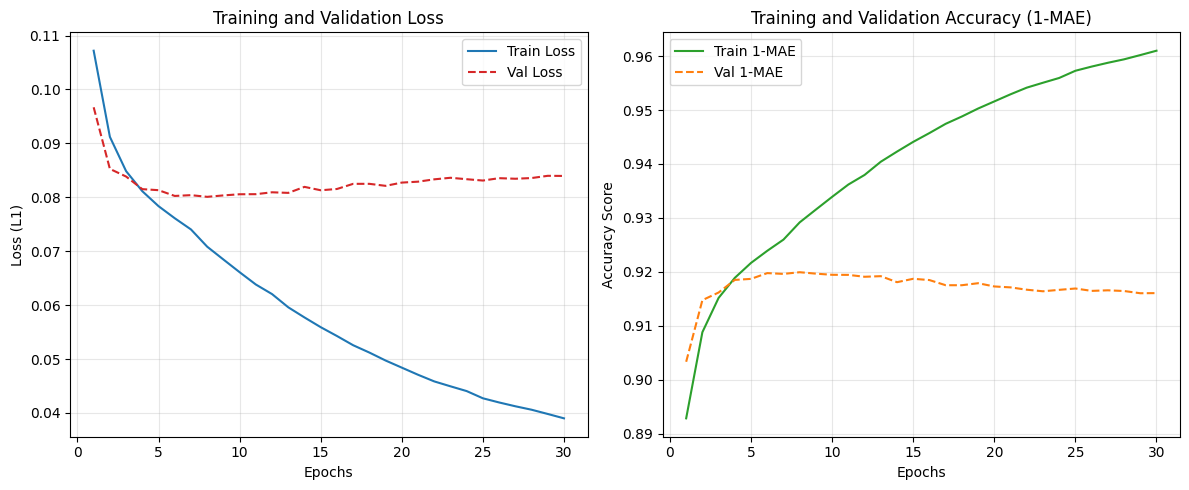

✅ 모든 프로세스가 완료되었습니다. 그래프: learning_results.png


In [ ]:
import os
import torch
import torch.nn as nn
import numpy as np
import clip
import laion_clap
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from tqdm import tqdm
from peft import LoraConfig, get_peft_model

# 직접 만든 모듈 import
from llama_model import PersonalityLLM
from h5personalityDataset import H5PersonalityDataset 

# ==========================================
# 1. 경로 및 하이퍼파라미터 설정
# ==========================================
device = "cuda" if torch.cuda.is_available() else "cpu"
BATCH_SIZE = 16
EPOCHS = 30
LR = 1e-6
TRAIN_H5 = "train_data_final.h5"
VAL_H5 = "val_data_final.h5"

# ==========================================
# 2. 모델 및 인코더 초기화
# ==========================================
print("🚀 모델 및 Frozen 인코더 로딩 중...")
clip_model, _ = clip.load("ViT-L/14", device=device)
clap_model = laion_clap.CLAP_Module(enable_fusion=False).to(device)
clap_model.load_ckpt() 

model = PersonalityLLM(device=device).to(device)

# 가중치 정밀도 설정 (Llama 3 bfloat16 호환)
model.video_projector.to(torch.bfloat16)
model.audio_projector.to(torch.bfloat16)
model.regression_head.to(torch.float32)

# LoRA 적용
lora_config = LoraConfig(
    r=16, lora_alpha=32,
    target_modules=["q_proj", "v_proj", "k_proj", "o_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    modules_to_save=["embed_tokens"]  # <--- 이 부분을 추가하여 스페셜 토큰 임베딩이 학습되게 합니다.
)
model.llama = get_peft_model(model.llama, lora_config)
model.llama.print_trainable_parameters()

# ==========================================
# 3. 데이터셋 및 고속 로더 준비
# ==========================================
if not os.path.exists(TRAIN_H5) or not os.path.exists(VAL_H5):
    raise FileNotFoundError("H5 파일이 존재하지 않습니다. 전처리 스크립트를 먼저 실행하세요.")

train_dataset = H5PersonalityDataset(TRAIN_H5)
val_dataset = H5PersonalityDataset(VAL_H5)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=8, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=8, pin_memory=True)

# ==========================================
# 4. 최적화 도구 및 기록용 리스트
# ==========================================
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
criterion = nn.L1Loss() 

def get_accuracy(pred, target):
    return 1 - torch.abs(pred - target).mean()

# 결과 기록용 딕셔너리
history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_acc': []
}
best_acc = -1e9

# ==========================================
# 5. 메인 학습 루프
# ==========================================
for epoch in range(EPOCHS):
    # --- TRAIN ---
    model.train()
    train_loss_sum, train_acc_sum = 0.0, 0.0
    pbar = tqdm(train_loader, desc=f"🔥 [TRAIN] Ep {epoch+1}/{EPOCHS}")
    
    for batch in pbar:
        videos = batch["video"].to(device)           # (B, 16, 3, 224, 224)
        audios = batch["audio"].to(device).float()   # (B, Samples)
        target_labels = batch["label"].to(device)
        transcriptions = batch["transcription"]
        b = videos.shape[0]

        with torch.no_grad():
            # CLIP 특징 추출
            v_feat = clip_model.encode_image(videos.view(-1, 3, 224, 224))
            v_feat = v_feat.view(b, 16, -1).mean(dim=1).to(torch.bfloat16)
            # CLAP 특징 추출
            a_feat = clap_model.get_audio_embedding_from_data(x=audios, use_tensor=True)
            if isinstance(a_feat, np.ndarray): a_feat = torch.from_numpy(a_feat).to(device)
            a_feat = a_feat.to(torch.bfloat16)

        prompts = [
                    f"The person said: '{t}'. Based on this speech, video, and audio, determine the Big5 personality scores." 
                    if t.strip() else "Determine the Big5 personality scores based on the video and audio."
                    for t in transcriptions
                ]        
        
        inputs = model.tokenizer(
            prompts, 
            return_tensors="pt", 
            padding=True, 
            truncation=True, 
            max_length=256 # 적절한 길이 제한
        ).to(device)

        preds = model(
            input_ids=inputs.input_ids, 
            video_features=v_feat, 
            audio_features=a_feat,
            attention_mask=inputs.attention_mask # 마스크 전달 필수
        )
        loss = criterion(preds, target_labels)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        acc = get_accuracy(preds.detach(), target_labels)
        train_loss_sum += loss.item()
        train_acc_sum += acc.item()
        pbar.set_postfix({"Loss": f"{loss.item():.4f}", "Acc": f"{acc.item():.4f}"})

    # Train 결과 저장
    history['train_loss'].append(train_loss_sum / len(train_loader))
    history['train_acc'].append(train_acc_sum / len(train_loader))

    # --- VALIDATION ---
    model.eval()
    val_loss_sum, val_acc_sum = 0.0, 0.0
    with torch.no_grad():
        for batch in tqdm(val_loader, desc="🛡️ [VAL]"):
            videos = batch["video"].to(device)
            audios = batch["audio"].to(device).float()
            target_labels = batch["label"].to(device)
            transcriptions = batch["transcription"]
            b = videos.shape[0]

            v_feat = clip_model.encode_image(videos.view(-1, 3, 224, 224)).view(b, 16, -1).mean(dim=1).to(torch.bfloat16)
            a_feat = clap_model.get_audio_embedding_from_data(x=audios, use_tensor=True)
            if isinstance(a_feat, np.ndarray): a_feat = torch.from_numpy(a_feat).to(device)
            a_feat = a_feat.to(torch.bfloat16)

            prompts = [
                f"The person said: '{t}'. Based on this speech, video, and audio, determine the Big5 personality scores." 
                if t.strip() else "Determine the Big5 personality scores based on the video and audio."
                for t in transcriptions
            ]
            inputs = model.tokenizer(prompts, return_tensors="pt", padding=True, truncation=True, max_length=256).to(device)
            
            preds = model(inputs.input_ids, v_feat, a_feat, attention_mask=inputs.attention_mask)
            
            val_loss_sum += criterion(preds, target_labels).item()
            val_acc_sum += get_accuracy(preds, target_labels).item()

    # Val 결과 저장
    avg_val_loss = val_loss_sum / len(val_loader)
    avg_val_acc = val_acc_sum / len(val_loader)
    history['val_loss'].append(avg_val_loss)
    history['val_acc'].append(avg_val_acc)

    print(f"📊 Result Ep {epoch+1} | Val Loss: {avg_val_loss:.4f} | Val 1-MAE: {avg_val_acc:.4f}")

    if avg_val_acc > best_acc:
        best_acc = avg_val_acc
        torch.save(model.state_dict(), "best_personality_model.pt")
        print("🏆 New Best Model Saved!\n")

# ==========================================
# 6. 학습 결과 시각화
# ==========================================
print("\n📈 학습 결과 그래프 생성 중...")
epochs_range = range(1, EPOCHS + 1)
plt.figure(figsize=(12, 5))

# Loss 그래프
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['train_loss'], label='Train Loss', color='#1f77b4')
plt.plot(epochs_range, history['val_loss'], label='Val Loss', color='#d62728', linestyle='--')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss (L1)')
plt.legend()
plt.grid(True, alpha=0.3)

# Accuracy 그래프
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['train_acc'], label='Train 1-MAE', color='#2ca02c')
plt.plot(epochs_range, history['val_acc'], label='Val 1-MAE', color='#ff7f0e', linestyle='--')
plt.title('Training and Validation Accuracy (1-MAE)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy Score')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('learning_results.png')
plt.show()

print("✅ 모든 프로세스가 완료되었습니다. 그래프: learning_results.png")
